## Load the data

In [3]:
import json
import numpy as np

with open("tallinn_osrm_matrix.json", "r", encoding="utf-8") as f:
    data = json.load(f)

# Number of locations, including depot
n = 5

# Location names
names = [point["name"] for point in data["points"][:n]]

# Distance matrix in kilometres
distances = np.array(data["distances"], dtype=float)[:n, :n] / 1000

print("Locations:")
for i, name in enumerate(names):
    print(f"{i}: {name}")

print("\nDistance matrix (km):")
print(np.round(distances, 2))

Locations:
0: Omniva Pallasti (depot)
1: Kadriorg President's Office
2: Shaurma Kebab Punane
3: Kultuurikatel
4: Patarei Prison

Distance matrix (km):
[[0.   2.68 2.77 3.94 5.14]
 [2.91 0.   4.47 3.22 4.42]
 [2.75 5.21 0.   6.13 7.33]
 [4.22 3.48 6.83 0.   1.39]
 [5.16 4.42 7.77 1.62 0.  ]]


## Optimal route with classical algorithm

In [4]:
from itertools import permutations

def calculate_distance(route, distances):
    return sum(
        distances[route[i], route[i + 1]]
        for i in range(len(route) - 1)
    )

best_distance = float("inf")
best_route = None

# Depot (0) is fixed at the start and end
for order in permutations(range(1, n)):
    route = (0,) + order + (0,)

    total_distance = calculate_distance(route, distances)

    if total_distance < best_distance:
        best_distance = total_distance
        best_route = route

print("Optimal route:")
print(" → ".join(names[i] for i in best_route))

print(f"\nMinimum distance: {best_distance:.2f} km")

Optimal route:
Omniva Pallasti (depot) → Kultuurikatel → Patarei Prison → Kadriorg President's Office → Shaurma Kebab Punane → Omniva Pallasti (depot)

Minimum distance: 16.96 km


## Visualization

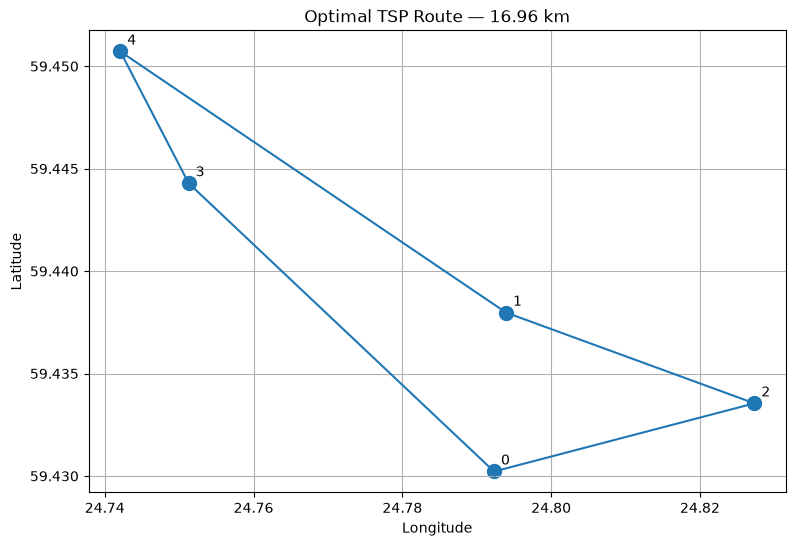

In [5]:
import matplotlib.pyplot as plt

# Coordinates of selected locations
latitudes = [p["lat"] for p in data["points"][:n]]
longitudes = [p["lon"] for p in data["points"][:n]]

plt.figure(figsize=(9, 6))

# Draw locations
plt.scatter(longitudes, latitudes, s=100)

# Draw route
route_lons = [longitudes[i] for i in best_route]
route_lats = [latitudes[i] for i in best_route]

plt.plot(route_lons, route_lats, marker="o")

for i, name in enumerate(names):
    plt.annotate(str(i), (longitudes[i], latitudes[i]),
                 xytext=(5, 5), textcoords="offset points")

plt.title(f"Optimal TSP Route — {best_distance:.2f} km")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(True)
plt.show()

## TSP formulation as QUBO

In [6]:
from qiskit_optimization import QuadraticProgram

qp = QuadraticProgram("Omniva_TSP")

m = n - 1  # Number of delivery locations

# Binary variables: x[i, p] = 1 if location i is visited at position p
for i in range(1, n):
    for p in range(m):
        qp.binary_var(name=f"x_{i}_{p}")

# Objective: minimize total driving distance
linear = {}
quadratic = {}

# Depot -> first delivery
for i in range(1, n):
    linear[f"x_{i}_0"] = distances[0, i]

# Last delivery -> depot
for i in range(1, n):
    name = f"x_{i}_{m-1}"
    linear[name] = linear.get(name, 0) + distances[i, 0]

# Distances between consecutive deliveries
for p in range(m - 1):
    for i in range(1, n):
        for j in range(1, n):
            if i != j:
                quadratic[(f"x_{i}_{p}", f"x_{j}_{p+1}")] = distances[i, j]

qp.minimize(linear=linear, quadratic=quadratic)

# Every location must be visited exactly once
for i in range(1, n):
    qp.linear_constraint(
        linear={f"x_{i}_{p}": 1 for p in range(m)},
        sense="==",
        rhs=1,
        name=f"visit_{i}"
    )

# Every route position must contain exactly one location
for p in range(m):
    qp.linear_constraint(
        linear={f"x_{i}_{p}": 1 for i in range(1, n)},
        sense="==",
        rhs=1,
        name=f"position_{p}"
    )

print(qp.prettyprint())

Problem name: Omniva_TSP

Minimize
  4.471*x_1_0*x_2_1 + 3.221*x_1_0*x_3_1 + 4.42*x_1_0*x_4_1 + 5.207*x_1_1*x_2_0
  + 4.471*x_1_1*x_2_2 + 3.479*x_1_1*x_3_0 + 3.221*x_1_1*x_3_2
  + 4.423*x_1_1*x_4_0 + 4.42*x_1_1*x_4_2 + 5.207*x_1_2*x_2_1 + 4.471*x_1_2*x_2_3
  + 3.479*x_1_2*x_3_1 + 3.221*x_1_2*x_3_3 + 4.423*x_1_2*x_4_1 + 4.42*x_1_2*x_4_3
  + 5.207*x_1_3*x_2_2 + 3.479*x_1_3*x_3_2 + 4.423*x_1_3*x_4_2
  + 6.134*x_2_0*x_3_1 + 7.334*x_2_0*x_4_1 + 6.826*x_2_1*x_3_0
  + 6.134*x_2_1*x_3_2 + 7.77*x_2_1*x_4_0 + 7.334*x_2_1*x_4_2 + 6.826*x_2_2*x_3_1
  + 6.134*x_2_2*x_3_3 + 7.77*x_2_2*x_4_1 + 7.334*x_2_2*x_4_3 + 6.826*x_2_3*x_3_2
  + 7.77*x_2_3*x_4_2 + 1.387*x_3_0*x_4_1 + 1.625*x_3_1*x_4_0 + 1.387*x_3_1*x_4_2
  + 1.625*x_3_2*x_4_1 + 1.387*x_3_2*x_4_3 + 1.625*x_3_3*x_4_2 + 2.676*x_1_0
  + 2.909*x_1_3 + 2.768*x_2_0 + 2.747*x_2_3 + 3.937*x_3_0 + 4.219*x_3_3
  + 5.136*x_4_0 + 5.163*x_4_3

Subject to
  Linear constraints (8)
    x_1_0 + x_1_1 + x_1_2 + x_1_3 == 1  'visit_1'
    x_2_0 + x_2_1 + x_2_2 + x_

## QUBO -> Ising Hamiltonian

In [7]:
from qiskit_optimization.converters import QuadraticProgramToQubo

# Convert constrained optimization problem to QUBO
penalty = 100

converter = QuadraticProgramToQubo(penalty=penalty)
qubo = converter.convert(qp)

# Convert QUBO to Ising Hamiltonian
H_raw, offset = qubo.to_ising()

# Scale Hamiltonian
H = (H_raw / penalty).simplify()

print("QUBO variables:", qubo.get_num_binary_vars())
print("Qubits:", H.num_qubits)
print("Hamiltonian terms:", len(H))

QUBO variables: 16
Qubits: 16
Hamiltonian terms: 100


## Check QUBO

In [8]:
import numpy as np

# Optimal route without depot
delivery_order = best_route[1:-1]

# Encode route as binary variables
assignment = {
    f"x_{i}_{p}": int(delivery_order[p] == i)
    for i in range(1, n)
    for p in range(m)
}

x = np.array([
    assignment[var.name]
    for var in qp.variables
])

print("Optimal route:", best_route)
print("Classical distance:", best_distance)
print("QP objective:", qp.objective.evaluate(x))
print("QUBO objective:", qubo.objective.evaluate(x))
print("Constraints satisfied:", qp.is_feasible(x))

Optimal route: (0, 3, 4, 1, 2, 0)
Classical distance: 16.965
QP objective: 16.965
QUBO objective: 16.965000000000146
Constraints satisfied: True


## QAOA circuit

In [9]:
from qiskit.circuit.library import QAOAAnsatz
from qiskit import transpile

REPS = 2  # Start with one QAOA layer

ansatz = QAOAAnsatz(
    cost_operator=H,
    reps=REPS
)

# Transpile to basic gates for statevector simulation
ansatz = transpile(
    ansatz,
    basis_gates=["h", "rx", "rz", "cx"],
    optimization_level=1
)

print("Qubits:", ansatz.num_qubits)
print("Parameters:", ansatz.num_parameters)
print("Circuit depth:", ansatz.depth())

Qubits: 16
Parameters: 4
Circuit depth: 134


## QAOA optimization

In [10]:
from qiskit.quantum_info import Statevector
from scipy.optimize import minimize
import numpy as np

# Hamiltonian used for optimization
H_matrix = H

def qaoa_cost(params):
    # Assign gamma and beta values
    circuit = ansatz.assign_parameters(params)

    # Simulate quantum circuit
    state = Statevector.from_instruction(circuit)

    # Calculate expected energy
    energy = np.real(state.expectation_value(H_matrix))

    return energy

# Initial parameters
initial_params = np.full(ansatz.num_parameters, 0.5)

# Optimize QAOA parameters
result = minimize(
    qaoa_cost,
    initial_params,
    method="COBYLA",
    options={"maxiter": 200}
)

print("Optimization finished!")
print("Optimal parameters:", result.x)
print("Minimum energy:", result.fun)
print("Iterations:", result.nfev)

Optimization finished!
Optimal parameters: [-0.49611165  2.95888332  0.16861332  0.5228545 ]
Minimum energy: -13.45915627841851
Iterations: 200


## QAOA result

In [11]:
from itertools import permutations
from qiskit.quantum_info import Statevector
import numpy as np

# 1. Simulate the optimized QAOA circuit
optimized_circuit = ansatz.assign_parameters(result.x)
state = Statevector.from_instruction(optimized_circuit)
probabilities = state.probabilities()

# 2. Generate all valid TSP routes
valid_routes = []

for order in permutations(range(1, n)):
    route = (0,) + order + (0,)

    # Encode the route into binary variables
    assignment = {
        f"x_{i}_{p}": int(order[p] == i)
        for i in range(1, n)
        for p in range(m)
    }

    bits = np.array([
        assignment[var.name]
        for var in qp.variables
    ])

    # Convert binary variables to statevector index
    index = sum(int(bit) << i for i, bit in enumerate(bits))

    probability = probabilities[index]
    distance = calculate_distance(route, distances)

    valid_routes.append((route, distance, probability))

# 3. Calculate total valid-route probability
valid_probability = sum(
    probability
    for route, distance, probability in valid_routes
)

# 4. Calculate optimal-route probability
optimal_probability = sum(
    probability
    for route, distance, probability in valid_routes
    if np.isclose(distance, best_distance)
)

# 5. Find the most probable VALID route
best_qaoa_route = max(
    valid_routes,
    key=lambda item: item[2]
)

# 6. Print results
print("=== QAOA RESULTS ===")
print(f"Classical optimum: {best_distance:.3f} km")
print(f"Valid route probability: {valid_probability * 100:.4f}%")
print(f"Optimal route probability: {optimal_probability * 100:.4f}%")

print("\nMost probable valid route:")
print(" -> ".join(map(str, best_qaoa_route[0])))
print(f"Distance: {best_qaoa_route[1]:.3f} km")
print(f"Probability: {best_qaoa_route[2] * 100:.4f}%")

=== QAOA RESULTS ===
Classical optimum: 16.965 km
Valid route probability: 7.5965%
Optimal route probability: 0.3249%

Most probable valid route:
0 -> 4 -> 3 -> 1 -> 2 -> 0
Distance: 17.458 km
Probability: 0.3250%


## Average distance among valid routes, weighted by their QAOA probabilities

In [12]:
weighted_distance = sum(
    distance * probability
    for route, distance, probability in valid_routes
)

average_valid_distance = weighted_distance / valid_probability

print("=== ROUTE QUALITY ===")
print(f"Classical optimum: {best_distance:.3f} km")
print(f"Average valid route distance: {average_valid_distance:.3f} km")
print(f"Difference: {average_valid_distance - best_distance:.3f} km")

=== ROUTE QUALITY ===
Classical optimum: 16.965 km
Average valid route distance: 21.407 km
Difference: 4.442 km


## FIND THE BEST ROUTE FROM QAOA MEASUREMENTS

In [13]:
from qiskit.quantum_info import Statevector
import numpy as np

shots = 10_000

# Use the best previously found REPS=2 parameters
circuit = ansatz.assign_parameters(result.x)

state = Statevector.from_instruction(circuit)

# Simulate measurements
state.seed(42)
counts = state.sample_counts(shots=shots)

best_sampled_route = None
best_sampled_distance = float("inf")
valid_measurements = 0

for bitstring, count in counts.items():

    # Convert Qiskit bitstring to QUBO variable order
    bits = np.array([int(b) for b in bitstring[::-1]])

    # Ignore invalid routes
    if not qp.is_feasible(bits):
        continue

    valid_measurements += count

    # Decode route
    order = []

    for p in range(m):
        for i in range(1, n):
            var_name = f"x_{i}_{p}"
            var_index = qp.variables_index[var_name]

            if bits[var_index] == 1:
                order.append(i)
                break

    route = (0,) + tuple(order) + (0,)
    distance = calculate_distance(route, distances)

    if distance < best_sampled_distance:
        best_sampled_distance = distance
        best_sampled_route = route

print("=== BEST SAMPLED QAOA ROUTE ===")
print("Shots:", shots)
print("Valid measurements:", valid_measurements)
print("Best sampled route:", best_sampled_route)
print(f"Distance: {best_sampled_distance:.3f} km")
print(f"Classical optimum: {best_distance:.3f} km")

=== BEST SAMPLED QAOA ROUTE ===
Shots: 10000
Valid measurements: 741
Best sampled route: (0, 3, 4, 1, 2, 0)
Distance: 16.965 km
Classical optimum: 16.965 km


## Random Baseline - comparison with QAOA

In [14]:
import numpy as np

shots = 10_000
rng = np.random.default_rng(42)

random_bits = rng.integers(
    0, 2,
    size=(shots, qp.get_num_binary_vars())
)

valid_count = 0
optimal_count = 0

for bits in random_bits:
    if qp.is_feasible(bits):
        valid_count += 1

        distance = qp.objective.evaluate(bits)

        if np.isclose(distance, best_distance):
            optimal_count += 1

print("=== RANDOM BASELINE ===")
print("Shots:", shots)
print("Valid measurements:", valid_count)
print("Optimal measurements:", optimal_count)
print(f"Valid rate: {valid_count / shots * 100:.4f}%")
print(f"Optimal rate: {optimal_count / shots * 100:.4f}%")

=== RANDOM BASELINE ===
Shots: 10000
Valid measurements: 5
Optimal measurements: 1
Valid rate: 0.0500%
Optimal rate: 0.0100%


## QAOA: comparison of different shot counts

In [15]:
from qiskit.quantum_info import Statevector
import numpy as np

circuit = ansatz.assign_parameters(result.x)
state = Statevector.from_instruction(circuit)

for shots in [100, 500, 1000, 10000]:
    state.seed(42)
    counts = state.sample_counts(shots=shots)

    valid_count = 0
    best_sampled_distance = float("inf")

    for bitstring, count in counts.items():
        bits = np.array([int(b) for b in bitstring[::-1]])

        if qp.is_feasible(bits):
            valid_count += count
            distance = qp.objective.evaluate(bits)
            best_sampled_distance = min(best_sampled_distance, distance)

    best_text = (
        f"{best_sampled_distance:.3f} km"
        if valid_count > 0 else "No valid route"
    )

    print(
        f"Shots: {shots:5d} | "
        f"Valid: {valid_count:4d} | "
        f"Best distance: {best_text}"
    )

Shots:   100 | Valid:   10 | Best distance: 18.115 km
Shots:   500 | Valid:   41 | Best distance: 17.458 km
Shots:  1000 | Valid:   77 | Best distance: 16.965 km
Shots: 10000 | Valid:  741 | Best distance: 16.965 km


## Connect to IBM Quantum Hardware

In [28]:
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService()

real_backend = service.least_busy(
    operational=True,
    simulator=False,
    min_num_qubits=16
)

print("Selected QPU:", real_backend.name)

qiskit_runtime_service.__init__:WARNING:2026-11-12 23:56:21,325: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-11-12 23:56:21,584: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2026-11-12 23:56:24,010: Using instance: open-instance, plan: open


Selected QPU: ibm_kingston


## Prepare QAOA Circuit for Real Hardware

In [29]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# Use the existing optimized QAOA circuit
qpu_circuit = ansatz.assign_parameters(result.x)
qpu_circuit.measure_all()

# Transpile for the real quantum computer
pm_real = generate_preset_pass_manager(
    backend=real_backend,
    optimization_level=3
)

isa_circuit = pm_real.run(qpu_circuit)

print("Qubits:", isa_circuit.num_qubits)
print("Circuit depth:", isa_circuit.depth())
print("Gate counts:", isa_circuit.count_ops())

Qubits: 156
Circuit depth: 925
Gate counts: OrderedDict({'sx': 1641, 'rz': 915, 'cz': 863, 'measure': 16, 'x': 15, 'barrier': 1})


## Execute QAOA on Real Quantum Hardware

In [30]:
from qiskit_ibm_runtime import SamplerV2

# Run the transpiled QAOA circuit on the real QPU
real_sampler = SamplerV2(mode=real_backend)

job = real_sampler.run(
    [isa_circuit],
    shots=256
)

print("Job ID:", job.job_id())

qiskit_runtime_service.backends:WARNING:2026-11-12 23:57:11,286: Using instance: open-instance, plan: open


Job ID: dbr3ce6jjaos73ai8j20


## Retrieve Real Quantum Hardware Results

Job status: DONE
Total shots: 256
Unique bitstrings: 242


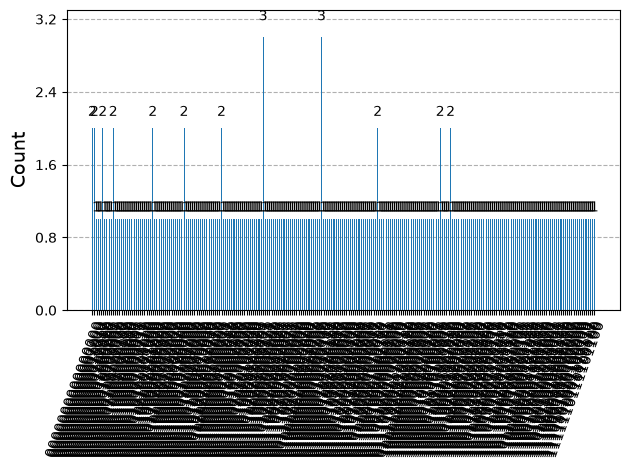

In [32]:
from qiskit.visualization import plot_histogram
from IPython.display import display

# Retrieve results from the completed quantum job
real_result = job.result()
real_counts = real_result[0].data.meas.get_counts()

print("Job status:", job.status())
print("Total shots:", sum(real_counts.values()))
print("Unique bitstrings:", len(real_counts))

display(plot_histogram(real_counts))

## Real Quantum Hardware Measurement Distribution

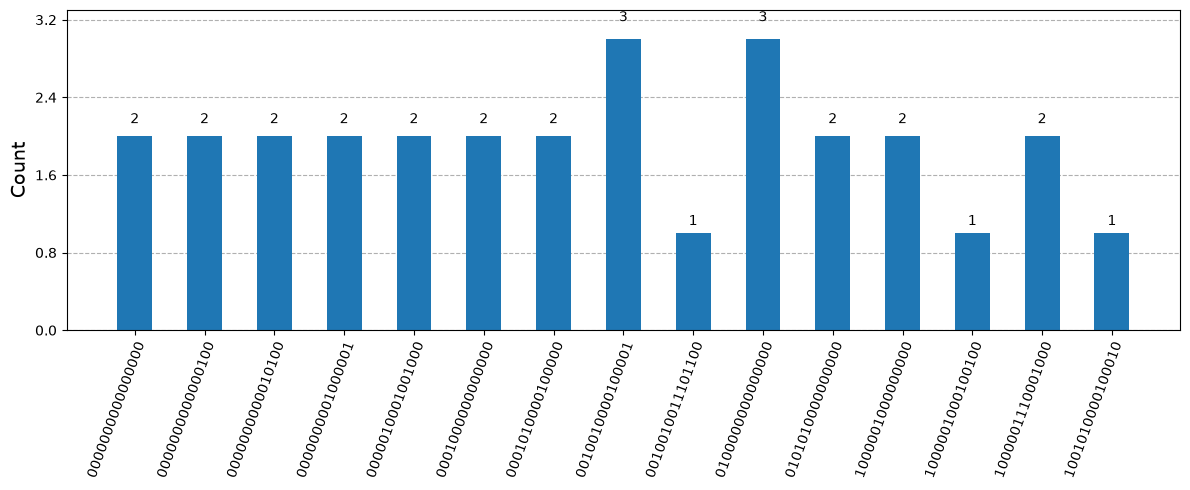

In [33]:
from qiskit.visualization import plot_histogram
from IPython.display import display

# Show only the 15 most frequent measurement outcomes
top_counts = dict(
    sorted(real_counts.items(), key=lambda x: x[1], reverse=True)[:15]
)

display(plot_histogram(top_counts, figsize=(12, 5)))

## Evaluate Real Quantum Hardware Success Rate

In [35]:
import numpy as np

# Check all real QPU measurements using the existing TSP constraints
valid_shots = 0
optimal_shots = 0
best_real_distance = float("inf")
best_real_route = None

for bitstring, count in real_counts.items():
    # Convert Qiskit bitstring to QUBO variable order
    bits = np.array([int(b) for b in bitstring[::-1]])

    if not qp.is_feasible(bits):
        continue

    valid_shots += count

    distance = qp.objective.evaluate(bits)

    if np.isclose(distance, best_distance):
        optimal_shots += count

    if distance < best_real_distance:
        best_real_distance = distance

total_shots = sum(real_counts.values())

print("=== REAL QUANTUM HARDWARE RESULTS ===")
print("Total shots:", total_shots)
print("Valid measurements:", valid_shots)
print("Optimal measurements:", optimal_shots)
print(f"Valid rate: {valid_shots / total_shots:.2%}")
print(f"Optimal rate: {optimal_shots / total_shots:.2%}")

if valid_shots > 0:
    print(f"Best valid route distance: {best_real_distance:.3f} km")
else:
    print("Best valid route: None")

=== REAL QUANTUM HARDWARE RESULTS ===
Total shots: 256
Valid measurements: 3
Optimal measurements: 0
Valid rate: 1.17%
Optimal rate: 0.00%
Best valid route distance: 18.294 km


## Results Visualization: Route Distance Comparison

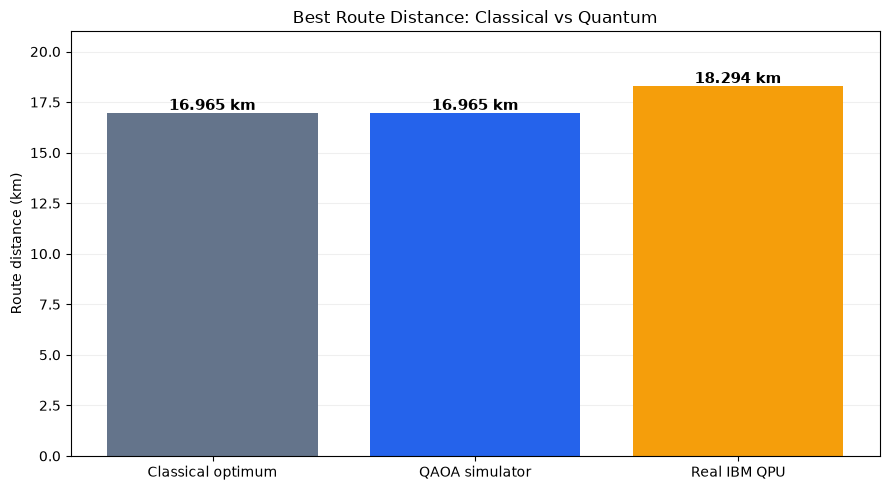

In [1]:
import matplotlib.pyplot as plt

# Best route distances from existing experiments
methods = ["Classical optimum", "QAOA simulator", "Real IBM QPU"]
recorded_distances = [16.965, 16.965, 18.294]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(methods, recorded_distances, color=["#64748b", "#2563eb", "#f59e0b"])

for bar, distance in zip(bars, recorded_distances):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        distance + 0.15,
        f"{distance:.3f} km",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_ylabel("Route distance (km)")
ax.set_title("Best Route Distance: Classical vs Quantum")
ax.set_ylim(0, 21)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## Results Visualization: Valid Solution Rate

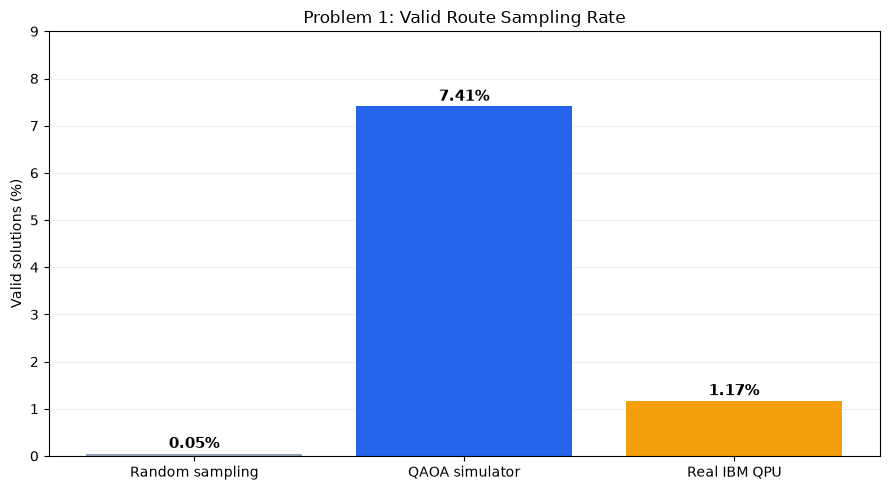

In [37]:
import matplotlib.pyplot as plt

# Valid solution rates from Problem 1 experiments
methods = ["Random sampling", "QAOA simulator", "Real IBM QPU"]
valid_rates = [0.05, 7.41, 1.17]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    methods,
    valid_rates,
    color=["#94a3b8", "#2563eb", "#f59e0b"]
)

for bar, rate in zip(bars, valid_rates):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        rate + 0.12,
        f"{rate:.2f}%",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_ylabel("Valid solutions (%)")
ax.set_title("Problem 1: Valid Route Sampling Rate")
ax.set_ylim(0, 9)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## Scalability: Qubit Requirements by Deliveries and Couriers

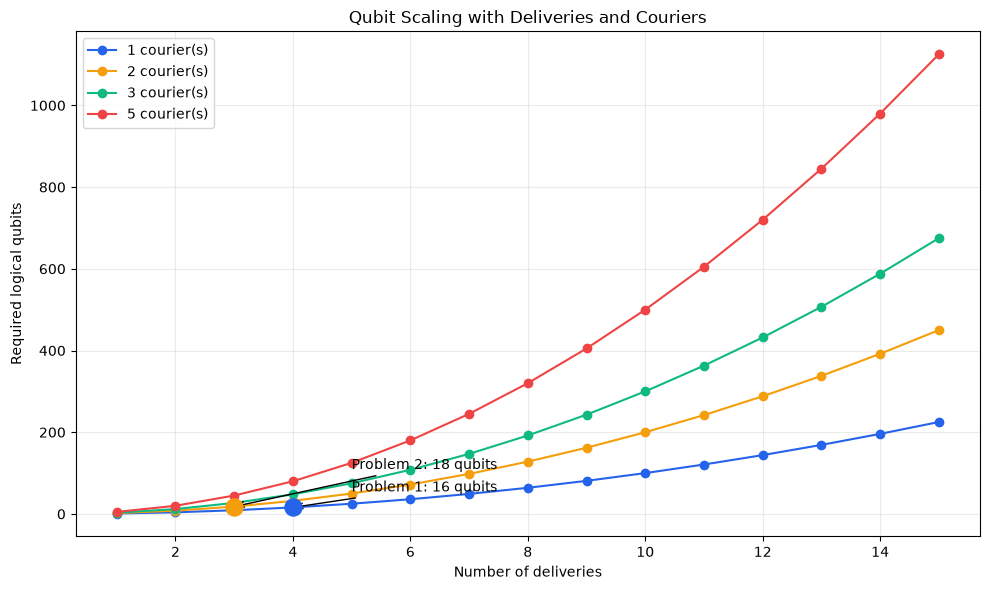

In [38]:
import numpy as np
import matplotlib.pyplot as plt

# Theoretical qubit requirements for our position-based encoding
deliveries = np.arange(1, 16)

fig, ax = plt.subplots(figsize=(10, 6))

for couriers, color in [
    (1, "#2563eb"),
    (2, "#f59e0b"),
    (3, "#10b981"),
    (5, "#ef4444"),
]:
    qubits = couriers * deliveries**2
    ax.plot(
        deliveries,
        qubits,
        marker="o",
        label=f"{couriers} courier(s)",
        color=color
    )

# Highlight our actual experiments
ax.scatter(4, 16, color="#2563eb", s=150, zorder=5)
ax.scatter(3, 18, color="#f59e0b", s=150, zorder=5)

ax.annotate("Problem 1: 16 qubits", (4, 16),
            xytext=(5, 55),
            arrowprops={"arrowstyle": "->"})

ax.annotate("Problem 2: 18 qubits", (3, 18),
            xytext=(5, 110),
            arrowprops={"arrowstyle": "->"})

ax.set_title("Qubit Scaling with Deliveries and Couriers")
ax.set_xlabel("Number of deliveries")
ax.set_ylabel("Required logical qubits")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

## Scalability: Classical Route Search Space

The chart shows the theoretical number of ordered delivery-route
assignments for different numbers of deliveries and couriers.

Every courier must receive at least one delivery.

Number of possible solutions:

R(n, k) = n! × C(n − 1, k − 1)

where:
- n = number of deliveries
- k = number of couriers
- C = binomial coefficient

This is a theoretical calculation, not a measured QAOA result.

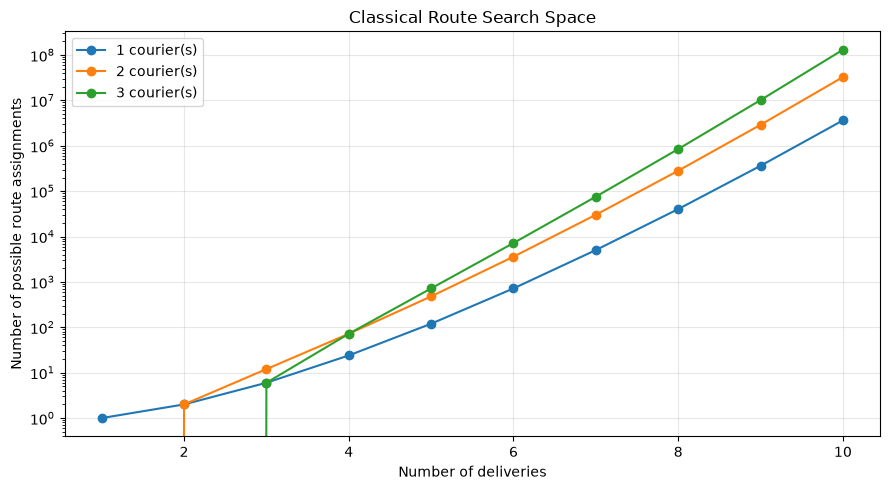

Problem 1: 24
Problem 2: 12


In [17]:
import math
import matplotlib.pyplot as plt

def count_routes(n, k):
    # Every courier must receive at least one delivery.
    if k > n:
        return 0

    return math.factorial(n) * math.comb(n - 1, k - 1)


deliveries = range(1, 11)

plt.figure(figsize=(9, 5))

for couriers in [1, 2, 3]:
    route_counts = [
        count_routes(n, couriers)
        for n in deliveries
    ]

    plt.plot(
        list(deliveries),
        route_counts,
        marker="o",
        label=f"{couriers} courier(s)"
    )

plt.yscale("log")
plt.xlabel("Number of deliveries")
plt.ylabel("Number of possible route assignments")
plt.title("Classical Route Search Space")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Problem 1:", count_routes(4, 1))  # 24
print("Problem 2:", count_routes(3, 2))  # 12

## Scalability: Quantum Simulation Memory Requirements

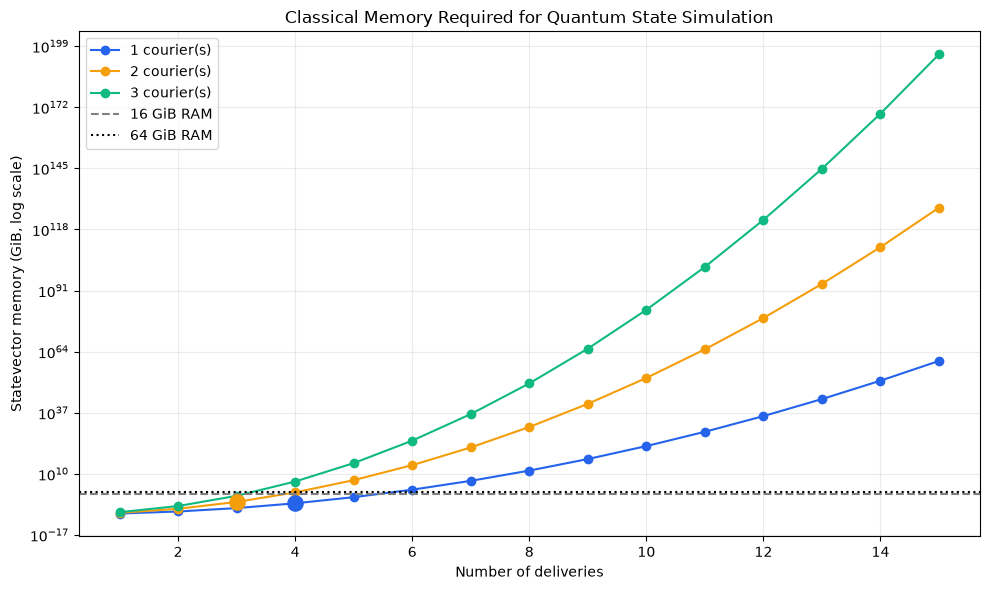

Problem 1 (16 qubits): 0.000977 GiB
Problem 2 (18 qubits): 0.003906 GiB
5 deliveries, 2 couriers: 16,777,216 GiB


In [40]:
import numpy as np
import matplotlib.pyplot as plt

# Theoretical scaling of our QUBO encodings
deliveries = np.arange(1, 16)

# Each complex128 statevector amplitude requires 16 bytes
def statevector_memory_gib(n, couriers):
    qubits = couriers * n**2
    return 16 * (2.0 ** qubits) / (1024**3)

fig, ax = plt.subplots(figsize=(10, 6))

for couriers, color in [
    (1, "#2563eb"),
    (2, "#f59e0b"),
    (3, "#10b981")
]:
    memory = [
        statevector_memory_gib(int(n), couriers)
        for n in deliveries
    ]

    ax.plot(
        deliveries,
        memory,
        marker="o",
        label=f"{couriers} courier(s)",
        color=color
    )

ax.axhline(16, linestyle="--", color="gray", label="16 GiB RAM")
ax.axhline(64, linestyle=":", color="black", label="64 GiB RAM")

ax.scatter(4, statevector_memory_gib(4, 1),
           color="#2563eb", s=120, zorder=5)

ax.scatter(3, statevector_memory_gib(3, 2),
           color="#f59e0b", s=120, zorder=5)

ax.set_yscale("log")
ax.set_xlabel("Number of deliveries")
ax.set_ylabel("Statevector memory (GiB, log scale)")
ax.set_title("Classical Memory Required for Quantum State Simulation")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

print("Problem 1 (16 qubits):",
      f"{statevector_memory_gib(4, 1):.6f} GiB")

print("Problem 2 (18 qubits):",
      f"{statevector_memory_gib(3, 2):.6f} GiB")

print("5 deliveries, 2 couriers:",
      f"{statevector_memory_gib(5, 2):,.0f} GiB")